In [4]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
class Detector:
    def __init__(self, R=2, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a

        self.pm_positions = self.generate_positions()

    def generate_positions(self):
        """Равномерное распределение фотоумножителей по сфере."""
        positions = []
        golden_angle = np.pi * (3 - np.sqrt(5))

        for i in range(self.N):
            z = 1 - 2 * (i + 0.5) / self.N
            theta = golden_angle * i
            rho = np.sqrt(1 - z**2)

            x = self.R * rho * np.cos(theta)
            y = self.R * rho * np.sin(theta)
            z = self.R * z

            positions.append([x, y, z])

        return np.array(positions)

    def is_on_detector(self, point, tol=1e-6):
        return abs(np.linalg.norm(point) - self.R) < tol

    def belongs_to_pm(self, point):
        """Проверяет, попадает ли точка в какой-либо фотоумножитель."""
        point = np.asarray(point)

        if not self.is_on_detector(point):
            return False

        cos_angles = self.pm_positions @ point / self.R**2
        cos_angles = np.clip(cos_angles, -1, 1)

        distances = self.R * np.arccos(cos_angles)

        return np.any(distances <= self.r)

    def find_photomultiplier(self, source, direction):
        """
        Определяет, в какой фотоумножитель попал фотон.
        Возвращает индекс фотоумножителя или None.
        """
        source = np.asarray(source)
        direction = np.asarray(direction)

        # Находим пересечение траектории со сферой
        dot = np.dot(source, direction)

        t = -dot + np.sqrt(
            dot**2 + self.R**2 - np.dot(source, source)
        )

        hit_point = source + t * direction

        # Проверяем расстояния до всех фотоумножителей
        cos_angles = self.pm_positions @ hit_point / self.R**2
        cos_angles = np.clip(cos_angles, -1, 1)

        distances = self.R * np.arccos(cos_angles)

        # Индексы фотоумножителей, на которые попал фотон
        hits = np.where(distances <= self.r)[0]

        if len(hits) == 0:
            return None

        return hits[0]

    def generate_photoelectrons(self, n_photons):
        """Разыгрывает количество фотоэлектронов."""
        return np.random.poisson(self.a * n_photons)

    def simulate_event(self, source, E, source_position):
        """
        Моделирует одно событие.
        Возвращает полный собранный заряд (число фотоэлектронов).
        """

        directions = source.generate_directions(E)

        source_position = np.asarray(source_position)

        # Пересечение траекторий фотонов со сферой
        dot = directions @ source_position

        t = -dot + np.sqrt(
            dot**2 + self.R**2 - np.dot(source_position, source_position)
        )

        hit_points = source_position + t[:, None] * directions

        # Проверяем угловое расстояние до центров фотоумножителей
        cos_angles = (hit_points / self.R) @ (self.pm_positions / self.R).T

        # Геодезический радиус фотоумножителя
        cos_limit = np.cos(self.r / self.R)

        # Фотон попал хотя бы в один фотоумножитель
        hits = np.max(cos_angles, axis=1) >= cos_limit

        n_hits = np.sum(hits)

        # Разыгрываем количество фотоэлектронов
        return np.random.poisson(self.a * n_hits)


In [11]:
class Source:
    def __init__(self, Y=10000):
        self.Y = Y

    def generate_directions(self, E):
        """Генерирует направления движения фотонов."""
        N = int(self.Y * E)

        phi = np.random.uniform(0, 2 * np.pi, N)
        cos_theta = np.random.uniform(-1, 1, N)
        sin_theta = np.sqrt(1 - cos_theta**2)

        directions = np.column_stack((
            sin_theta * np.cos(phi),
            sin_theta * np.sin(phi),
            cos_theta
        ))

        return directions


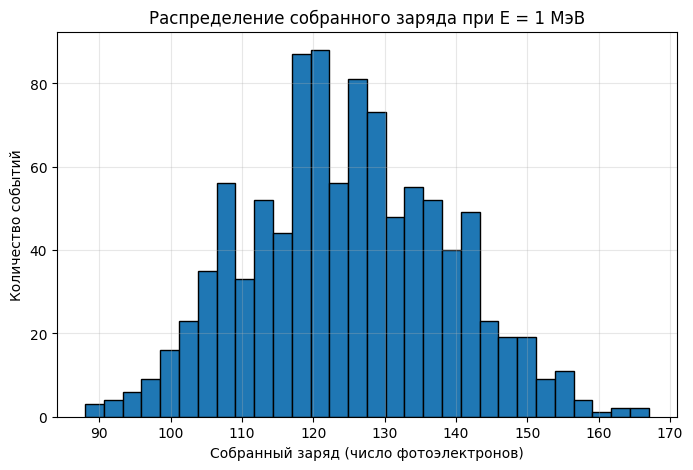

Среднее значение: 124.637
Стандартное отклонение: 13.865117109944382
Относительная ширина: 0.1112439894248448


In [15]:
def run_simulations(detector, source, E, position, n_events=1000):
    results = []

    for _ in range(n_events):
        Q = detector.simulate_event(source, E, position)
        results.append(Q)

    return np.array(results)


detector = Detector()
source = Source()

# Источник в центре детектора
center = np.array([0., 0., 0.])

# 1000 событий с энергией 1 МэВ
results = run_simulations(detector, source, 1.0, center)

# Строим распределение заряда
plt.figure(figsize=(8, 5))
plt.hist(results, bins=30, edgecolor='black')

plt.xlabel('Собранный заряд (число фотоэлектронов)')
plt.ylabel('Количество событий')
plt.title('Распределение собранного заряда при E = 1 МэВ')

plt.grid(alpha=0.3)
plt.show()

print("Среднее значение:", np.mean(results))
print("Стандартное отклонение:", np.std(results, ddof=1))
print("Относительная ширина:",
      np.std(results, ddof=1) / np.mean(results))


E = 0.2 MeV: mean = 24.89, std = 6.30, relative width = 0.2533
E = 0.5 MeV: mean = 62.41, std = 9.33, relative width = 0.1495
E = 0.7 MeV: mean = 87.75, std = 11.43, relative width = 0.1302
E = 1.0 MeV: mean = 124.68, std = 13.54, relative width = 0.1086
E = 1.5 MeV: mean = 187.80, std = 16.59, relative width = 0.0883
E = 2.0 MeV: mean = 250.08, std = 19.13, relative width = 0.0765
E = 3.0 MeV: mean = 372.94, std = 23.48, relative width = 0.0630


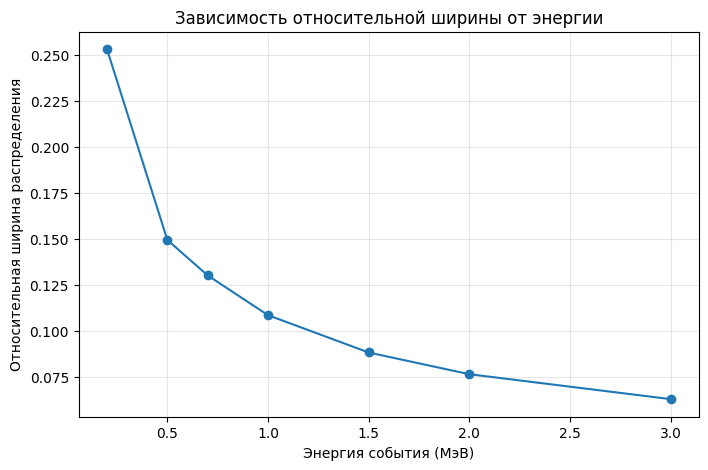

In [20]:
energies = [0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]

means = []
stds = []
relative_widths = []

for E in energies:
    results = run_simulations(
        detector, source, E, center, n_events=1000
    )

    mean = np.mean(results)
    std = np.std(results, ddof=1)
    relative_width = std / mean

    means.append(mean)
    stds.append(std)
    relative_widths.append(relative_width)

    print(
        f"E = {E:.1f} MeV: "
        f"mean = {mean:.2f}, "
        f"std = {std:.2f}, "
        f"relative width = {relative_width:.4f}"
    )

# График зависимости относительной ширины от энергии
plt.figure(figsize=(8, 5))
plt.plot(energies, relative_widths, 'o-')

plt.xlabel('Энергия события (МэВ)')
plt.ylabel('Относительная ширина распределения')
plt.title('Зависимость относительной ширины от энергии')

plt.grid(alpha=0.3)
plt.show()

Среднее значение заряда растёт линейно с энергией: ⟨Q⟩ ≈ 125·E. Относительная ширина распределения убывает как 1/√E. При N ∝ E число попаданий и число фотоэлектронов подчиняются статистике Пуассона, и σ_Q/⟨Q⟩ = √(187,5·E) / (125·E) ≈ 0,1095/√E

Центр:    124.61 ± 0.43
z = 1 м:  124.13 ± 0.43
Изменение: -0.39 %
Ширина (центр / сдвиг): 0.1095 / 0.1105


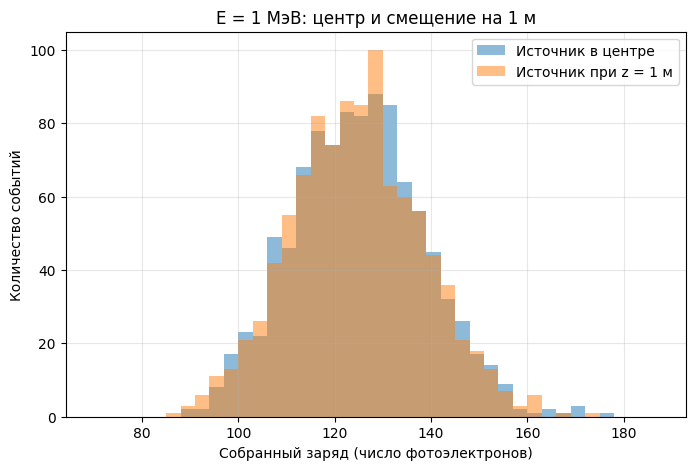

In [21]:
# Источник в центре и смещённый на 1 м по z, обе серии при E = 1 МэВ
center = np.array([0., 0., 0.])
shifted_position = np.array([0., 0., 1.])

res_center = run_simulations(detector, source, 1.0, center, n_events=1000)
res_shifted = run_simulations(detector, source, 1.0, shifted_position, n_events=1000)

mean_c, mean_s = res_center.mean(), res_shifted.mean()
err_c = res_center.std(ddof=1) / np.sqrt(len(res_center))
err_s = res_shifted.std(ddof=1) / np.sqrt(len(res_shifted))

print(f"Центр:    {mean_c:.2f} ± {err_c:.2f}")
print(f"z = 1 м:  {mean_s:.2f} ± {err_s:.2f}")
print(f"Изменение: {(mean_s - mean_c) / mean_c * 100:.2f} %")
print(f"Ширина (центр / сдвиг): {res_center.std(ddof=1)/mean_c:.4f} / {res_shifted.std(ddof=1)/mean_s:.4f}")

plt.figure(figsize=(8, 5))
bins = np.arange(70, 190, 3)
plt.hist(res_center, bins=bins, alpha=0.5, label='Источник в центре')
plt.hist(res_shifted, bins=bins, alpha=0.5, label='Источник при z = 1 м')
plt.xlabel('Собранный заряд (число фотоэлектронов)')
plt.ylabel('Количество событий')
plt.title('E = 1 МэВ: центр и смещение на 1 м')
plt.legend(); plt.grid(alpha=0.3); plt.show()

Разность средних значений не превышает статистическую неопределённость, поэтому заметного влияния смещения на средний собранный заряд в рамках проведённого моделирования не обнаружено.